<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Local uRNA background subtraction (tl.subtract_local_urna_background) and its effect on genes and cell types.
> - **Manuscript panels:** ED Fig. 7G-I
> - **Inputs:** `data_annotated_lambda0.5.zarr` (computed with `run_local_bg_msbrain.py`)
> - **Outputs:** Top changed genes, dotplots raw vs. corrected
> - **Environment / kernel:** `troutpy_updated`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# Local uRNA background decontamination -- msbrain 5k

Explores the output of `troutpy.tl.subtract_local_urna_background`: for every cell and gene, compares the cell's own (segmented) count against the density of that gene's genuinely-unassigned (uRNA) transcripts found within a fixed radius of the cell. If a cell's count is no larger than what ambient background at the locally-observed uRNA density would produce anyway, that count is not trustworthy as real expression -- regardless of which neighbor, if any, it might really belong to. See `troutpy/tl/decontamination.py` for the full model.

In [1]:
import sys, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import spatialdata as sd

matplotlib.rcParams["pdf.fonttype"] = 42
matplotlib.rcParams["ps.fonttype"] = 42

# Local package module source (overrides the installed troutpy package)
from troutpy import tl


## Load data and run the decontamination

In [2]:
data_dir = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_msbrain_5k")
saving_path = Path("/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/ms_figures/xenium_msbrain_5k/local_urna_background_decontamination")
saving_path.mkdir(parents=True, exist_ok=True)

sdata = sd.read_zarr(data_dir / "data_annotated.zarr")
sdata

no parent found for <ome_zarr.reader.Label object at 0x7f679f469730>: None


no parent found for <ome_zarr.reader.Label object at 0x7f679f4698e0>: None


SpatialData object, with associated Zarr store: /ictstr01/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_msbrain_5k/data_annotated.zarr
├── Images
│     └── 'morphology_focus': DataTree[cyx] (5, 9300, 8049), (5, 4650, 4025), (5, 2325, 2012), (5, 1162, 1006), (5, 581, 502)
├── Labels
│     ├── 'cell_labels': DataTree[yx] (9300, 8049), (4650, 4025), (2325, 2012), (1162, 1006), (581, 502)
│     └── 'nucleus_labels': DataTree[yx] (9300, 8049), (4650, 4025), (2325, 2012), (1162, 1006), (581, 502)
├── Points
│     ├── 'extracellular_transcripts': DataFrame with shape: (<Delayed>, 23) (3D points)
│     └── 'transcripts': DataFrame with shape: (<Delayed>, 28) (3D points)
├── Shapes
│     ├── 'cell_boundaries': GeoDataFrame shape: (9289, 1) (2D shapes)
│     ├── 'cell_circles': GeoDataFrame shape: (9191, 2) (2D shapes)
│     ├── 'grid_squares': GeoDataFrame shape: (34056, 1) (2D shapes)
│     └── 'nucleus_boundaries': GeoDataFrame shape: (9249, 1) (2D shapes)
└── Tables
    

In [3]:
RADIUS = 100.0  # microns
INNER_RADIUS = 10.0  # microns; excluded to avoid segmentation-boundary errors biasing the background estimate
tl.subtract_local_urna_background(sdata, radius=RADIUS, inner_radius=INNER_RADIUS)

Estimating local uRNA background for 9185 cells (annulus 10.0-100.0), using real segmentation areas...


Local background subtraction:   0%|          | 0/9185 [00:00<?, ?it/s]

Local background subtraction:   0%|          | 1/9185 [00:00<20:11,  7.58it/s]

Local background subtraction:   0%|          | 3/9185 [00:00<12:30, 12.23it/s]

Local background subtraction:   0%|          | 5/9185 [00:00<11:53, 12.87it/s]

...

Local background subtraction: 100%|█████████▉| 9182/9185 [14:11<00:00, 10.06it/s]

Local background subtraction: 100%|█████████▉| 9183/9185 [14:11<00:00,  9.92it/s]

Local background subtraction: 100%|█████████▉| 9184/9185 [14:11<00:00,  9.68it/s]

Local background subtraction: 100%|██████████| 9185/9185 [14:11<00:00, 10.79it/s]

Local background subtraction: removed 654105.8 counts total across 9185 cells (0 cells skipped for insufficient shape data).


## Extract raw vs. corrected matrices

`layers['raw']` is untouched by the function; `layers['decontaminated_density']` holds the corrected counts.

In [4]:
adata = sdata["table"]

def to_dense(m):
    return m.toarray() if hasattr(m, "toarray") else np.asarray(m)

raw = to_dense(adata.layers["raw"])
corr = to_dense(adata.layers["decontaminated_density"])
genes = adata.var_names.to_numpy()
cell_ids = adata.obs["cell_id"].to_numpy()
cell_types = adata.obs["cell_type"].to_numpy()

raw.shape, corr.shape

((9185, 4886), (9185, 4886))

## Per-gene change: which genes are most affected overall?

In [5]:
raw_total = raw.sum(axis=0)
corr_total = corr.sum(axis=0)
removed_total = raw_total - corr_total

gene_df = pd.DataFrame({
    "gene": genes,
    "raw_total": raw_total,
    "corrected_total": corr_total,
    "removed_total": removed_total,
    "fraction_removed": np.divide(removed_total, raw_total, out=np.zeros_like(raw_total), where=raw_total > 0),
})
gene_df.to_csv(saving_path / "local_background_gene_changes.csv", index=False)

MIN_RAW_TOTAL = 50
gene_df_f = gene_df[gene_df["raw_total"] >= MIN_RAW_TOTAL].copy()
top_genes = gene_df_f.sort_values("fraction_removed", ascending=False).head(20)
top_genes[["gene", "raw_total", "corrected_total", "fraction_removed"]]

,gene,raw_total,corrected_total,fraction_removed
4246,Sptbn2,7250.0,3036.964833,0.581108
530,Camk2a,49072.0,22518.822454,0.541106
2631,Map2,26368.0,14830.762772,0.437547
3093,Nsmf,28249.0,16523.488339,0.415077
2395,Kif5a,14776.0,8647.167889,0.414783
1180,Dlg4,15144.0,9677.918589,0.360940
2928,Ndrg2,17519.0,11862.956492,0.322852
4167,Snph,4795.0,3292.894835,0.313265
2062,Hpcal4,12343.0,8568.104332,0.305833
2330,Kcnab2,16451.0,11587.676724,0.295625


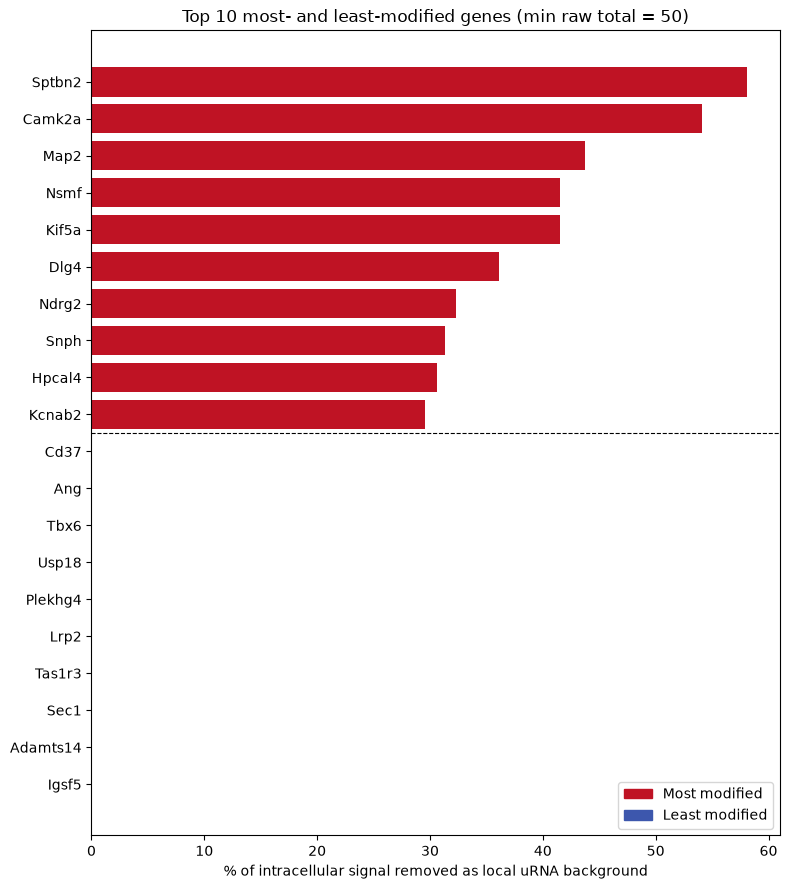

In [6]:
TOP_N_BAR = 10
top10 = gene_df_f.sort_values("fraction_removed", ascending=False).head(TOP_N_BAR)
bottom10 = gene_df_f.sort_values("fraction_removed", ascending=True).head(TOP_N_BAR)

combined = pd.concat([
    top10.assign(group="Most modified"),
    bottom10.sort_values("fraction_removed", ascending=False).assign(group="Least modified"),
]).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(8, 9))
colors = combined["group"].map({"Most modified": "#bf1324", "Least modified": "#3d57ad"})
y_pos = np.arange(len(combined))[::-1]
ax.barh(y_pos, combined["fraction_removed"] * 100, color=colors)
ax.set_yticks(y_pos)
ax.set_yticklabels(combined["gene"])
ax.axhline(y_pos[TOP_N_BAR - 1] - 0.5, color="black", linewidth=0.8, linestyle="--")
ax.set_xlabel("% of intracellular signal removed as local uRNA background")
ax.set_title(f"Top {TOP_N_BAR} most- and least-modified genes (min raw total = {MIN_RAW_TOTAL})")

handles = [plt.Rectangle((0, 0), 1, 1, color="#bf1324"), plt.Rectangle((0, 0), 1, 1, color="#3d57ad")]
ax.legend(handles, ["Most modified", "Least modified"], loc="lower right")
plt.tight_layout()
fig.savefig(saving_path / "top_changed_genes_barh.pdf", format="pdf", bbox_inches="tight")
plt.show()


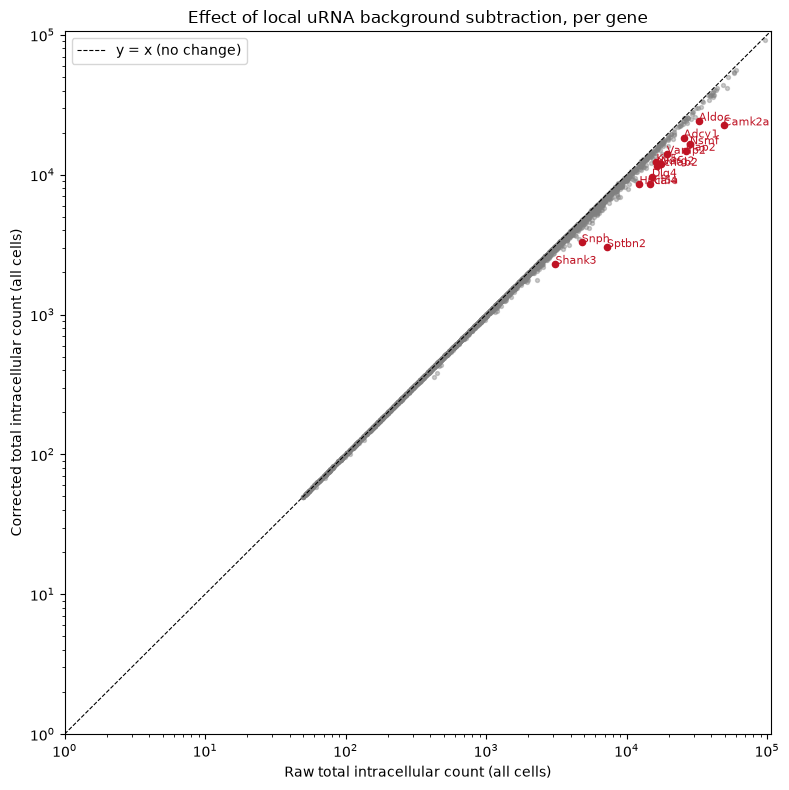

In [7]:
fig2, ax2 = plt.subplots(figsize=(8, 8))
ax2.scatter(gene_df_f["raw_total"], gene_df_f["corrected_total"], s=8, alpha=0.4, color="gray")
lims = [1, max(gene_df_f["raw_total"].max(), gene_df_f["corrected_total"].max()) * 1.1]
ax2.plot(lims, lims, "--", color="black", linewidth=0.8, label="y = x (no change)")
top_labeled = top_genes.head(15)
ax2.scatter(top_labeled["raw_total"], top_labeled["corrected_total"], s=20, color="#bf1324", zorder=3)
for _, row in top_labeled.iterrows():
    ax2.annotate(row["gene"], (row["raw_total"], row["corrected_total"]), fontsize=8, color="#bf1324")
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlim(lims); ax2.set_ylim(lims)
ax2.set_xlabel("Raw total intracellular count (all cells)")
ax2.set_ylabel("Corrected total intracellular count (all cells)")
ax2.set_title("Effect of local uRNA background subtraction, per gene")
ax2.legend()
plt.tight_layout()
fig2.savefig(saving_path / "raw_vs_corrected_scatter.png", dpi=150)
plt.show()

## Per-cell change: which cells lost the most signal?

For each cell, total counts removed (summed over all genes), and that as a fraction of the cell's own total (raw) transcript count -- a cell losing a lot in absolute terms might just be a high-count cell; the fraction shows how much of *that cell's own* signal was ambient-background-like.

In [8]:
removed_per_cell = raw.sum(axis=1) - corr.sum(axis=1)
raw_per_cell_total = raw.sum(axis=1)

cell_df = pd.DataFrame({
    "cell_id": cell_ids,
    "cell_type": cell_types,
    "raw_total": raw_per_cell_total,
    "removed_total": removed_per_cell,
    "fraction_removed": np.divide(removed_per_cell, raw_per_cell_total, out=np.zeros_like(removed_per_cell), where=raw_per_cell_total > 0),
})
cell_df.to_csv(saving_path / "local_background_cell_changes.csv", index=False)

MIN_CELL_TOTAL = 20
cell_df_f = cell_df[cell_df["raw_total"] >= MIN_CELL_TOTAL].copy()
top_cells_abs = cell_df_f.sort_values("removed_total", ascending=False).head(30)
top_cells_abs[["cell_id", "cell_type", "raw_total", "removed_total", "fraction_removed"]]

,cell_id,cell_type,raw_total,removed_total,fraction_removed
3273,koeenflo-1,CA3,7559.0,740.540505,0.097968
6787,mflopmak-1,CA3,6669.0,722.228374,0.108296
2858,klnggbid-1,CA3,7463.0,650.318847,0.087139
6339,mebhfpgd-1,CA3,6553.0,627.127131,0.095701
6307,mdpeajan-1,CA3,5686.0,609.874889,0.107259
6338,mebenenf-1,CA3,5858.0,609.141825,0.103985
2861,klnjioli-1,CA3,6613.0,550.324995,0.083219
3250,kocmhkfh-1,CA3,6210.0,534.482202,0.086068
3277,koeladne-1,CA3,5374.0,529.240895,0.098482
6685,mffjgnlp-1,CA3,6210.0,513.378242,0.082670


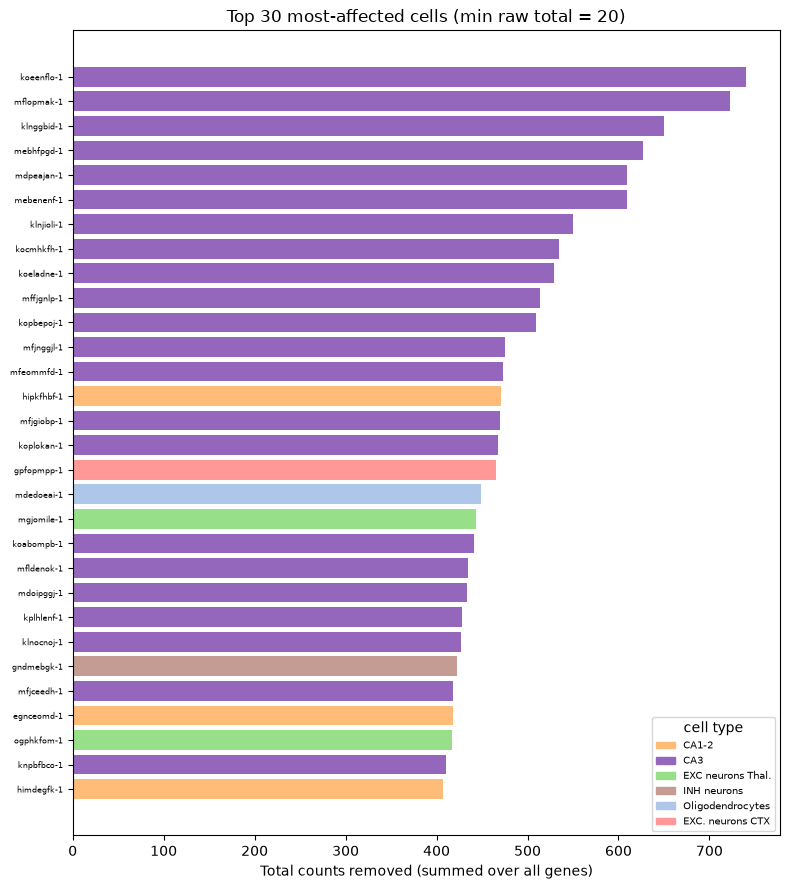

In [9]:
# Colour bars by cell type so it's visible whether the most-affected cells cluster in a few types
cell_type_order = cell_df_f["cell_type"].value_counts().index.tolist()
palette = dict(zip(cell_type_order, sns.color_palette("tab20", n_colors=len(cell_type_order))))

order = top_cells_abs.iloc[::-1]
colors = [palette[ct] for ct in order["cell_type"]]

fig, ax = plt.subplots(figsize=(8, 9))
ax.barh(range(len(order)), order["removed_total"], color=colors)
ax.set_yticks(range(len(order)))
ax.set_yticklabels(order["cell_id"], fontsize=6)
ax.set_xlabel("Total counts removed (summed over all genes)")
ax.set_title(f"Top 30 most-affected cells (min raw total = {MIN_CELL_TOTAL})")

handles = [plt.Rectangle((0, 0), 1, 1, color=palette[ct]) for ct in order["cell_type"].unique()]
ax.legend(handles, order["cell_type"].unique(), title="cell type", loc="lower right", fontsize=7)
plt.tight_layout()
fig.savefig(saving_path / "top_changed_cells_barh.png", dpi=150)
plt.show()

## Cell-type x gene: who is losing signal for the top-changed genes?

For the genes most affected overall, does the correction remove signal roughly evenly across all cell types, or specifically from cell types where the gene is less expected biologically (suggesting the removed signal really was contamination), while leaving it largely intact in its main expressing cell type? Only decreases are possible here (this method only ever subtracts), so the colormap is one-directional -- the interesting signal is in the *relative* magnitude across cell types, not the sign.

In [10]:
top_gene_list = top_genes["gene"].tolist()
gene_idx = {g: i for i, g in enumerate(genes)}
top_cols = [gene_idx[g] for g in top_gene_list]

raw_df = pd.DataFrame(raw[:, top_cols], columns=top_gene_list)
corr_df = pd.DataFrame(corr[:, top_cols], columns=top_gene_list)
raw_df["cell_type"] = cell_types
corr_df["cell_type"] = cell_types

raw_by_ct = raw_df.groupby("cell_type")[top_gene_list].mean()
corr_by_ct = corr_df.groupby("cell_type")[top_gene_list].mean()

pct_change = (corr_by_ct - raw_by_ct) / raw_by_ct.replace(0, np.nan) * 100
pct_change = pct_change.dropna(how="all")
pct_change.round(1)

,Sptbn2,Camk2a,Map2,Nsmf,Kif5a,Dlg4,Ndrg2,Snph,Hpcal4,Kcnab2,Adcy1,Vamp2,Shank3,Aldoc,Kif5c,Fbxl16,Arc,Adarb1,Camta2,Pink1
cell_type,,,,,,,,,,,,,,,,,,,,
Astrocytes,-58.2,-70.5,-45.0,-45.7,-45.6,-43.1,-21.0,-35.5,-39.6,-42.1,-55.7,-29.0,-23.5,-11.4,-32.1,-28.7,-26.9,-15.8,-26.2,-25.8
Astrocytes Thal.,-27.9,-62.7,-38.1,-54.5,-38.9,-37.7,-24.3,-18.8,-27.4,-35.0,-45.3,-42.0,-42.4,-17.0,-33.7,-15.1,-4.4,-50.4,-11.6,-36.5
CA1-2,-80.0,-69.7,-60.8,-59.8,-34.0,-50.8,-63.8,-52.5,-42.3,-40.2,-44.4,-40.5,-27.3,-60.5,-20.4,-44.5,-32.0,-7.0,-31.7,-25.9
CA3,-70.7,-50.6,-55.4,-47.5,-50.6,-37.7,-63.0,-41.7,-25.4,-23.1,-22.7,-29.4,-35.5,-59.9,-28.9,-31.3,-18.7,-19.8,-23.2,-22.3
Cajal-Retzius,-37.2,-89.1,-32.5,-62.8,-14.5,-38.0,-51.1,-26.6,-45.6,-39.3,-66.4,-13.4,-17.2,-39.4,-6.9,-22.5,-28.3,-10.9,-19.1,-14.8
Choroid plexus,-4.0,-15.2,-13.2,-8.9,-91.7,-7.9,-8.5,-1.9,-8.2,-3.2,-5.9,-9.0,-1.6,-55.6,-38.0,-5.9,NaN,-1.9,-1.7,-18.9
DG,-32.8,-37.9,-42.6,-27.4,-31.7,-24.1,-50.0,-17.6,-25.0,-18.6,-17.8,-19.7,-13.1,-55.8,-23.1,-15.6,-3.3,-7.4,-14.4,-14.8
EXC neurons Thal.,-28.4,-37.3,-34.4,-36.5,-20.0,-25.9,-35.7,-17.7,-13.9,-21.4,-26.6,-21.8,-38.1,-71.7,-14.9,-12.8,-1.6,-28.9,-12.8,-26.4
EXC. neurons CTX,-46.5,-36.5,-30.9,-32.7,-56.5,-30.2,-50.6,-23.9,-26.6,-17.7,-21.3,-23.6,-8.8,-52.2,-28.9,-18.6,-21.0,-9.5,-14.4,-28.0


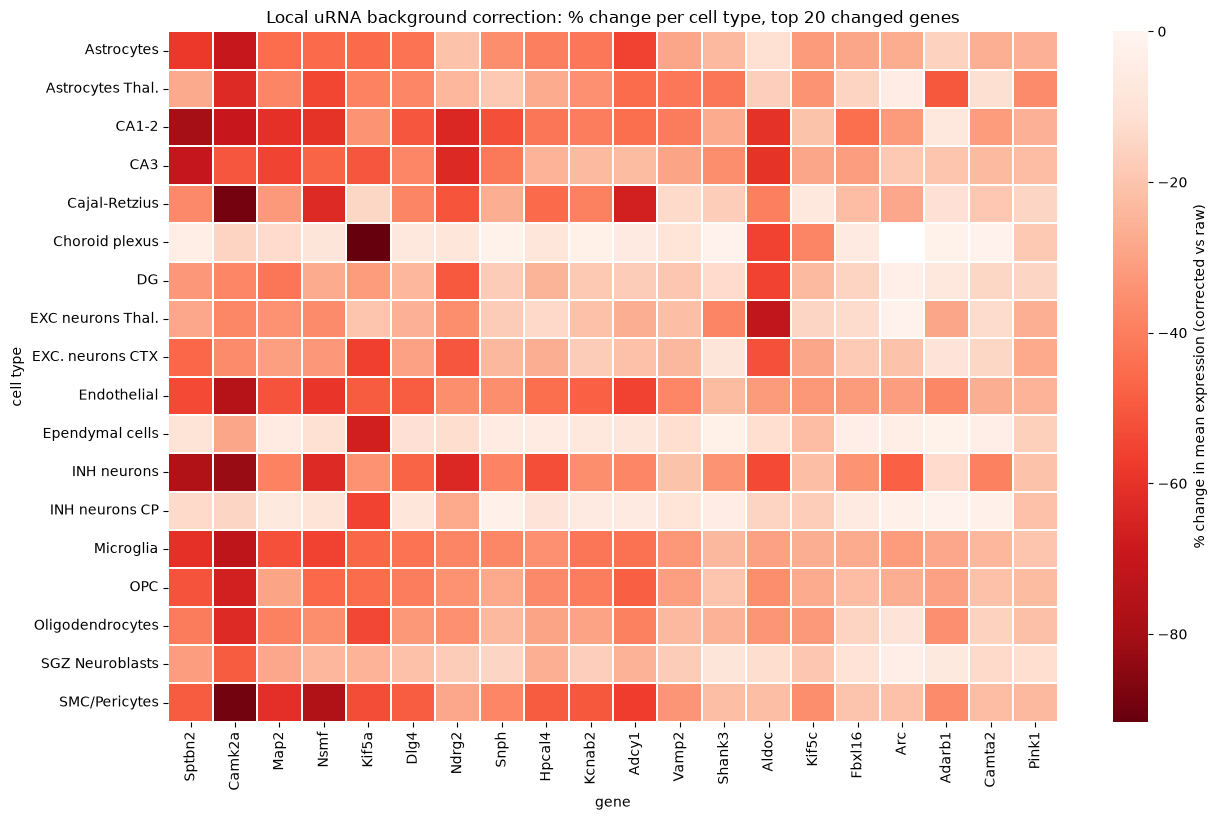

In [11]:
fig, ax = plt.subplots(figsize=(0.55 * len(top_gene_list) + 2, 0.35 * len(pct_change) + 2))
sns.heatmap(
    pct_change,
    cmap="Reds_r",
    vmax=0,
    cbar_kws={"label": "% change in mean expression (corrected vs raw)"},
    linewidths=0.3,
    linecolor="white",
    ax=ax,
)
ax.set_xlabel("gene")
ax.set_ylabel("cell type")
ax.set_title("Local uRNA background correction: % change per cell type, top 20 changed genes")
plt.tight_layout()
fig.savefig(saving_path / "celltype_by_gene_pct_change_heatmap.png", dpi=150)
plt.show()

## Cell-type x gene: absolute mean expression, raw vs. corrected side by side

The % change heatmap above can be dominated by cell types where a gene barely has any expression at all (a tiny absolute change can look like a huge % change). This second view shows the actual mean expression level itself, before and after, so you can judge whether a cell type's genuinely-expressing signal survives the correction.

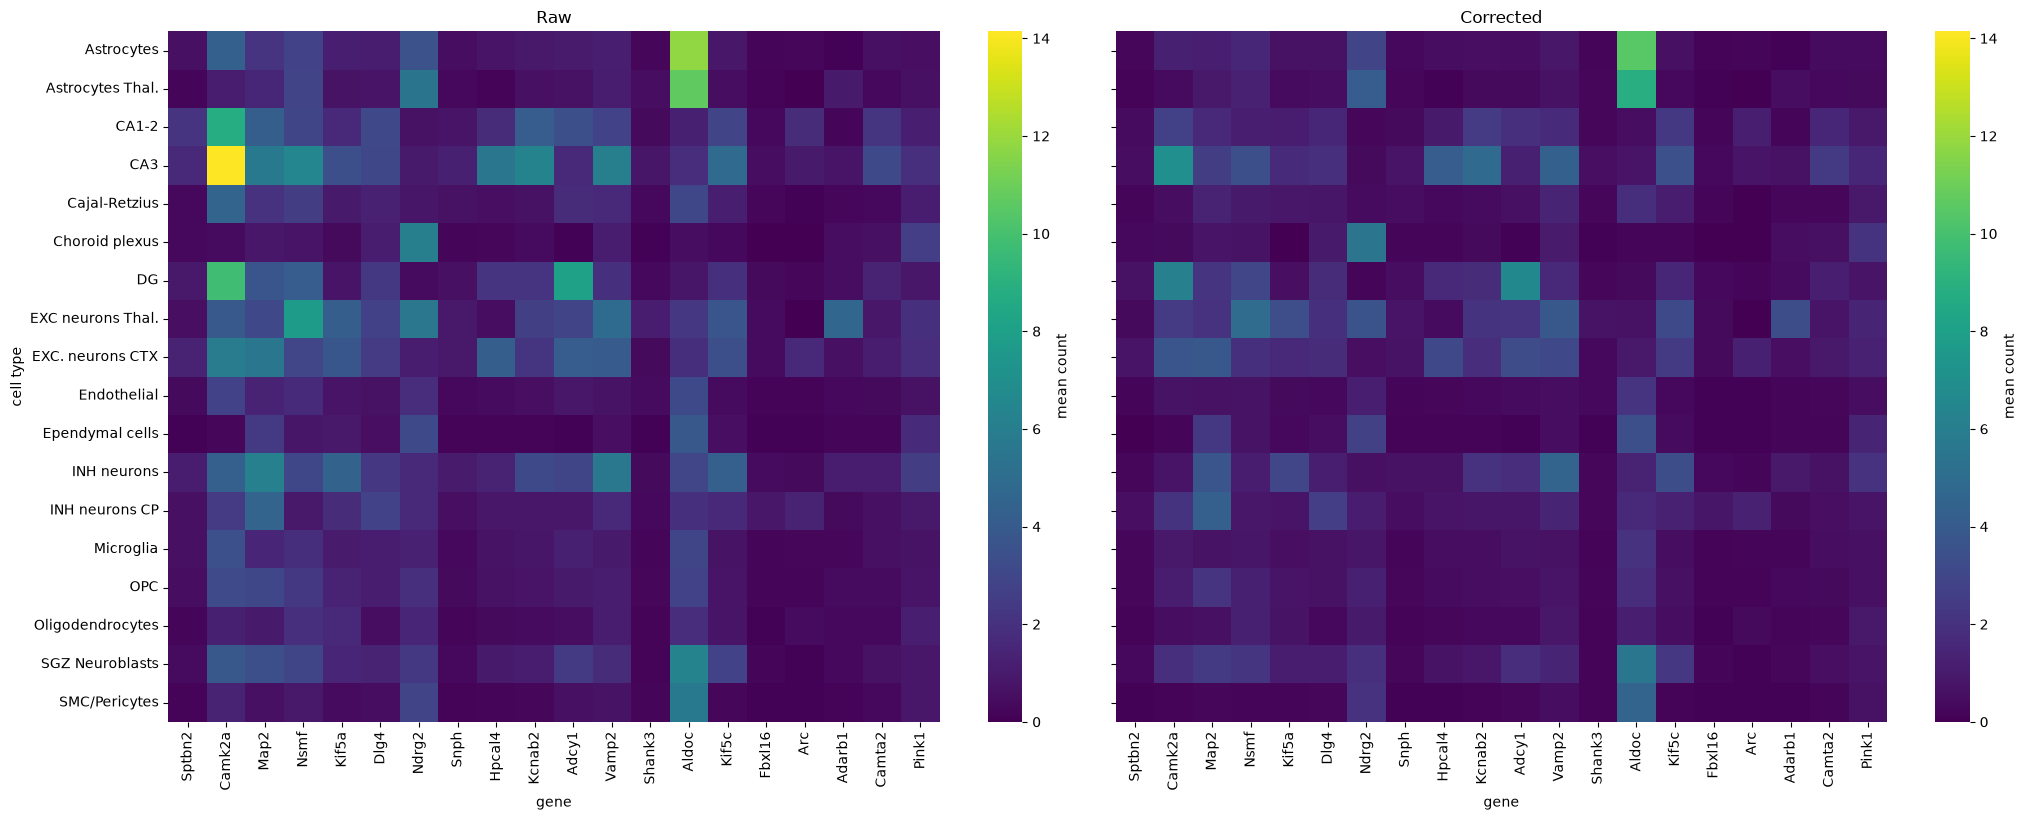

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(0.9 * len(top_gene_list) + 3, 0.35 * len(raw_by_ct) + 2), sharey=True)
vmax = max(raw_by_ct.loc[pct_change.index].values.max(), corr_by_ct.loc[pct_change.index].values.max())

sns.heatmap(raw_by_ct.loc[pct_change.index], cmap="viridis", vmin=0, vmax=vmax, ax=axes[0], cbar_kws={"label": "mean count"})
axes[0].set_title("Raw")
axes[0].set_xlabel("gene")
axes[0].set_ylabel("cell type")

sns.heatmap(corr_by_ct.loc[pct_change.index], cmap="viridis", vmin=0, vmax=vmax, ax=axes[1], cbar_kws={"label": "mean count"})
axes[1].set_title("Corrected")
axes[1].set_xlabel("gene")
axes[1].set_ylabel("")

plt.tight_layout()
fig.savefig(saving_path / "celltype_by_gene_raw_vs_corrected_heatmap.png", dpi=150)
plt.show()

## UMAP: cell types and top-gene expression, before vs. after decontamination

A single UMAP layout, computed once from the raw (pre-decontamination) log-normalized profile so both panels below share the same 2D coordinates -- only the *coloring* (expression values) differs between the raw and decontaminated panels, so any visual change reflects the correction itself, not a different embedding.

In [13]:
import scanpy as sc
import anndata as ad

# Independently normalize each version (raw vs decontaminated) so per-cell size
# factors reflect that version's own total counts -- appropriate since the
# decontamination itself changes some cells' totals more than others.
tmp_raw = ad.AnnData(X=raw.copy(), obs=adata.obs.copy(), var=adata.var.copy())
sc.pp.normalize_total(tmp_raw, target_sum=1e4)
sc.pp.log1p(tmp_raw)
adata.layers["raw_lognorm"] = tmp_raw.X.copy()

tmp_corr = ad.AnnData(X=corr.copy(), obs=adata.obs.copy(), var=adata.var.copy())
sc.pp.normalize_total(tmp_corr, target_sum=1e4)
sc.pp.log1p(tmp_corr)
adata.layers["decontam_lognorm"] = tmp_corr.X.copy()

# Shared embedding from the raw (pre-decontamination) profile -- this is the
# actual measured data, so the layout reflects real cell identity/clustering.
sc.pp.pca(tmp_raw, n_comps=50)
sc.pp.neighbors(tmp_raw)
sc.tl.umap(tmp_raw)
adata.obsm["X_umap"] = tmp_raw.obsm["X_umap"]

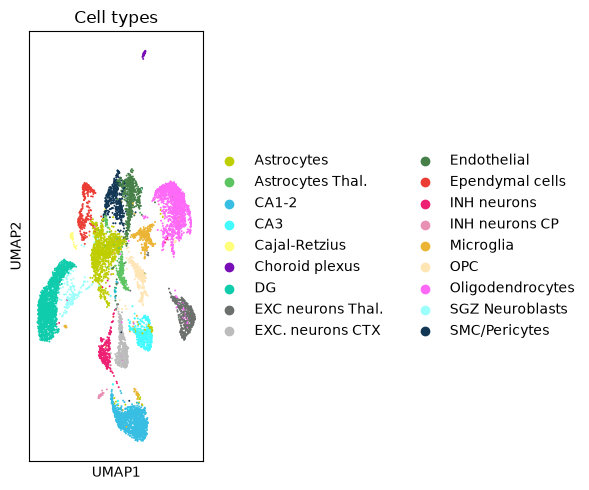

In [14]:
fig, ax = plt.subplots(figsize=(6, 5))
sc.pl.umap(adata, color="cell_type", ax=ax, show=False, size=8)
ax.set_title("Cell types")
plt.tight_layout()
fig.savefig(saving_path / "umap_cell_types.png", dpi=150, bbox_inches="tight")
plt.show()

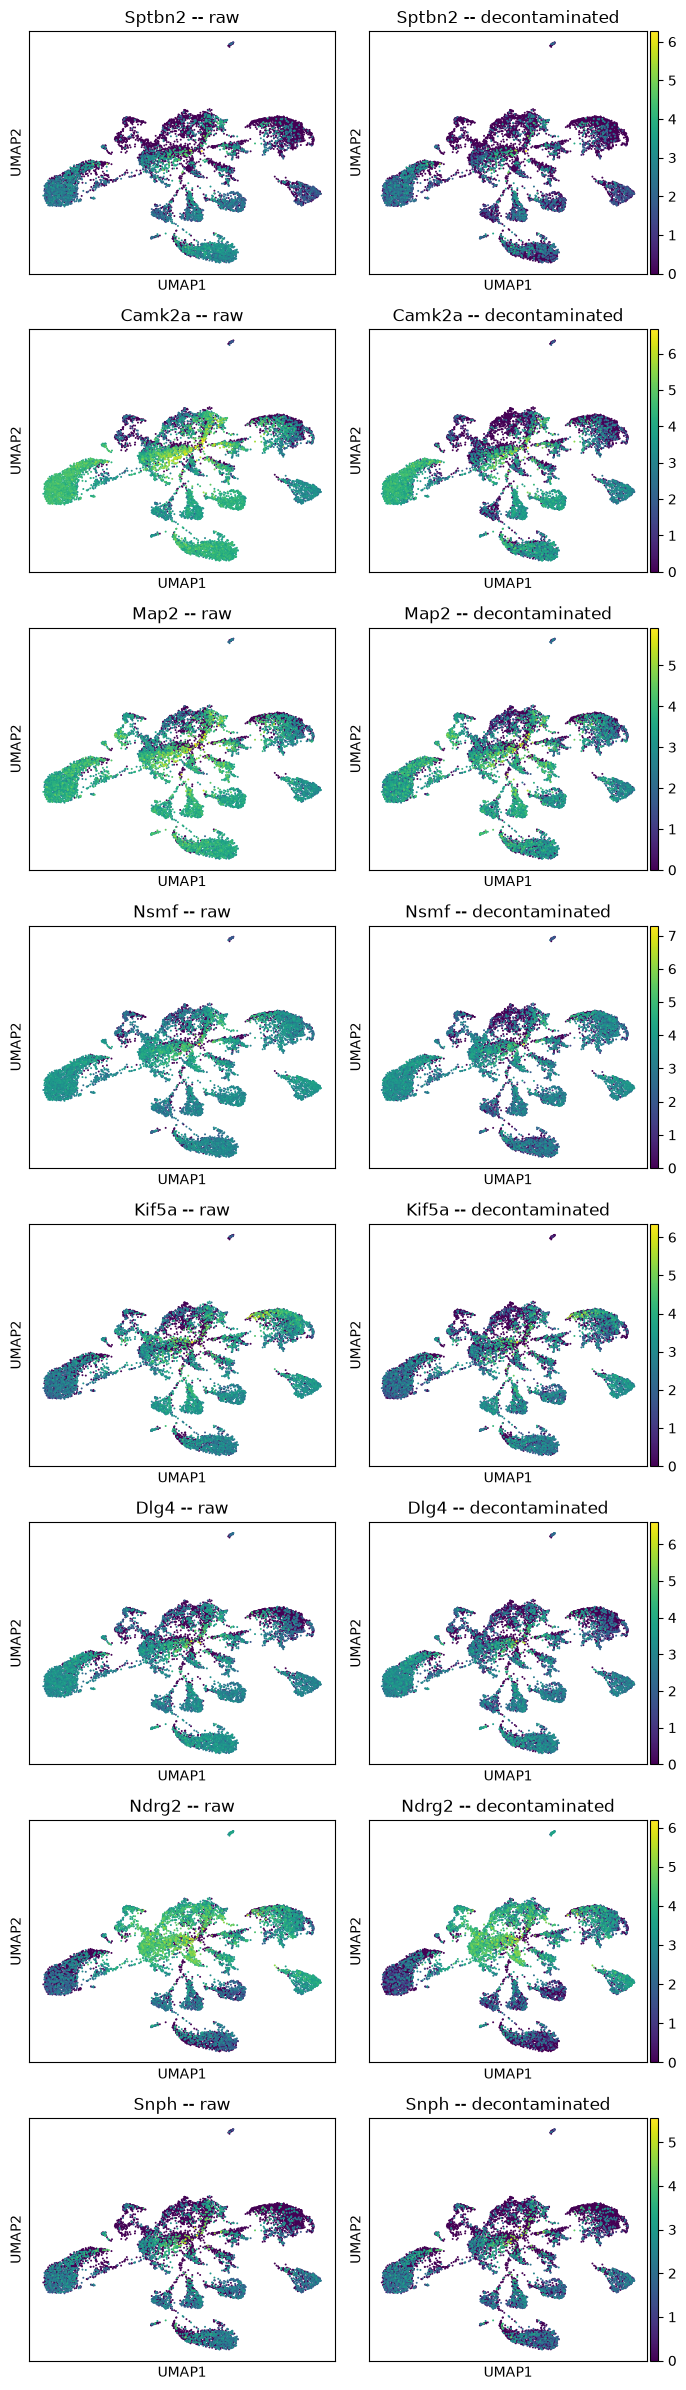

In [15]:
N_UMAP_GENES = 8
top_umap_genes = top_genes["gene"].head(N_UMAP_GENES).tolist()

fig, axes = plt.subplots(len(top_umap_genes), 2, figsize=(7, 3 * len(top_umap_genes)))

# Shared color scale per gene (across raw/decontaminated) so the two panels are
# directly comparable rather than each auto-scaling to its own range.
for i, gene in enumerate(top_umap_genes):
    vmax = max(adata.layers["raw_lognorm"][:, adata.var_names.get_loc(gene)].max(),
               adata.layers["decontam_lognorm"][:, adata.var_names.get_loc(gene)].max())
    sc.pl.umap(adata, color=gene, layer="raw_lognorm", ax=axes[i, 0], show=False,
               size=8, vmin=0, vmax=vmax, title=f"{gene} -- raw", colorbar_loc=None)
    sc.pl.umap(adata, color=gene, layer="decontam_lognorm", ax=axes[i, 1], show=False,
               size=8, vmin=0, vmax=vmax, title=f"{gene} -- decontaminated")

plt.tight_layout()
fig.savefig(saving_path / "umap_top_genes_raw_vs_decontaminated.png", dpi=150, bbox_inches="tight")
plt.show()

## Dotplots: paired expression across cell types, before vs. after cleaning

Standard scanpy dotplot (dot size = fraction of cells expressing, color = mean expression), one for the raw layer and one for the decontaminated layer, using the *same* gene order, cell-type order, and color scale so the two are directly comparable. First for the top-changed genes (most correction applied); then a second pair for the genes with the **smallest** correction among reasonably-expressed genes -- i.e. the ones the method left essentially untouched, which should look nearly identical before/after as a sanity check that the method isn't blindly removing signal everywhere.

In [16]:
def paired_dotplot_combined(gene_list, title, filename, cell_type_order=None):
    """One dotplot per gene set: for each cell type, an uncorrected dot (top) and a
    corrected dot (bottom), joined by a connecting line -- dot size = % cells
    expressing, color = mean log-normalized expression. Shared color scale across
    both conditions so they are directly comparable."""
    gene_cols = [adata.var_names.get_loc(g) for g in gene_list]
    ct = adata.obs["cell_type"].astype(str).values
    cats = cell_type_order if cell_type_order is not None else sorted(pd.unique(ct))

    raw_ln = adata.layers["raw_lognorm"][:, gene_cols]
    corr_ln = adata.layers["decontam_lognorm"][:, gene_cols]
    raw_expr = raw[:, gene_cols]
    corr_expr = corr[:, gene_cols]

    SLOT = 3.0    # vertical space allotted to each cell type
    OFFSET = 0.7  # distance of each dot from the cell type's center line

    rows = []
    for ci, cell_type in enumerate(cats):
        mask = ct == cell_type
        for gi, gene in enumerate(gene_list):
            rows.append({
                "cell_type": cell_type, "gene": gene, "condition": "uncorrected", "gi": gi,
                "y": ci * SLOT + OFFSET,
                "mean_expr": raw_ln[mask, gi].mean(), "pct_expr": (raw_expr[mask, gi] > 0).mean() * 100,
            })
            rows.append({
                "cell_type": cell_type, "gene": gene, "condition": "corrected", "gi": gi,
                "y": ci * SLOT - OFFSET,
                "mean_expr": corr_ln[mask, gi].mean(), "pct_expr": (corr_expr[mask, gi] > 0).mean() * 100,
            })
    df = pd.DataFrame(rows)
    vmax = df["mean_expr"].max()

    fig, ax = plt.subplots(figsize=(0.8 * len(gene_list) + 4, 0.75 * len(cats) + 2))

    for ci in range(len(cats)):
        for gi in range(len(gene_list)):
            ax.plot([gi, gi], [ci * SLOT + OFFSET, ci * SLOT - OFFSET], color="lightgray", linewidth=0.8, zorder=1)

    sc_ = ax.scatter(
        df["gi"], df["y"], s=df["pct_expr"] * 4 + 10, c=df["mean_expr"],
        cmap="Reds", vmin=0, vmax=vmax, edgecolor="black", linewidth=0.3, zorder=2,
    )

    # Explicit per-row condition labels, to the right of the last gene column
    label_x = len(gene_list) - 1 + 0.45
    for ci in range(len(cats)):
        ax.text(label_x, ci * SLOT + OFFSET, "uncorrected", fontsize=7, color="dimgray", va="center", ha="left")
        ax.text(label_x, ci * SLOT - OFFSET, "corrected", fontsize=7, color="dimgray", va="center", ha="left")

    ax.set_xticks(range(len(gene_list)))
    ax.set_xticklabels(gene_list, rotation=90)
    ax.set_yticks([ci * SLOT for ci in range(len(cats))])
    ax.set_yticklabels(cats)
    ax.set_xlim(-0.7, len(gene_list) + 1.6)
    ax.set_ylim(-1.5, len(cats) * SLOT)

    ax.text(0.0, 1.01, "\u25b2 uncorrected (top)   \u25bc corrected (bottom)", transform=ax.transAxes,
            fontsize=9, ha="left", va="bottom")

    cbar = plt.colorbar(sc_, ax=ax, fraction=0.03, pad=0.1)
    cbar.set_label("Mean expression (log-norm)")

    for pct in [25, 50, 75, 100]:
        ax.scatter([], [], s=pct * 4 + 10, color="gray", edgecolor="black", linewidth=0.3, label=f"{pct}%")
    ax.legend(title="% expressing", bbox_to_anchor=(1.38, 1), loc="upper left", fontsize=8, frameon=False)

    ax.set_title(title)
    plt.tight_layout()
    fig.savefig(saving_path / filename, format="pdf", bbox_inches="tight")
    plt.show()


### Top-changed genes (most correction applied) -- paired, uncorrected vs. corrected

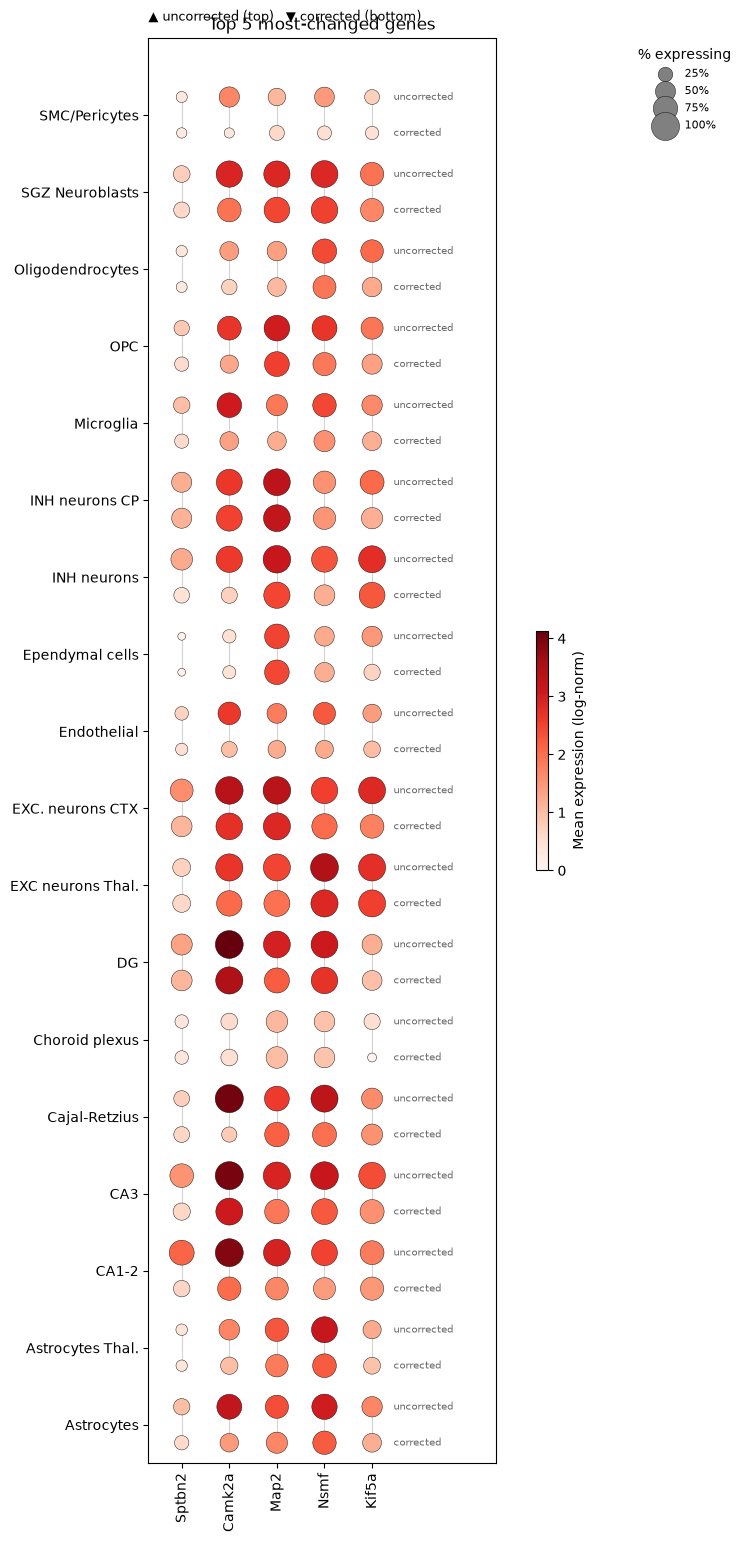

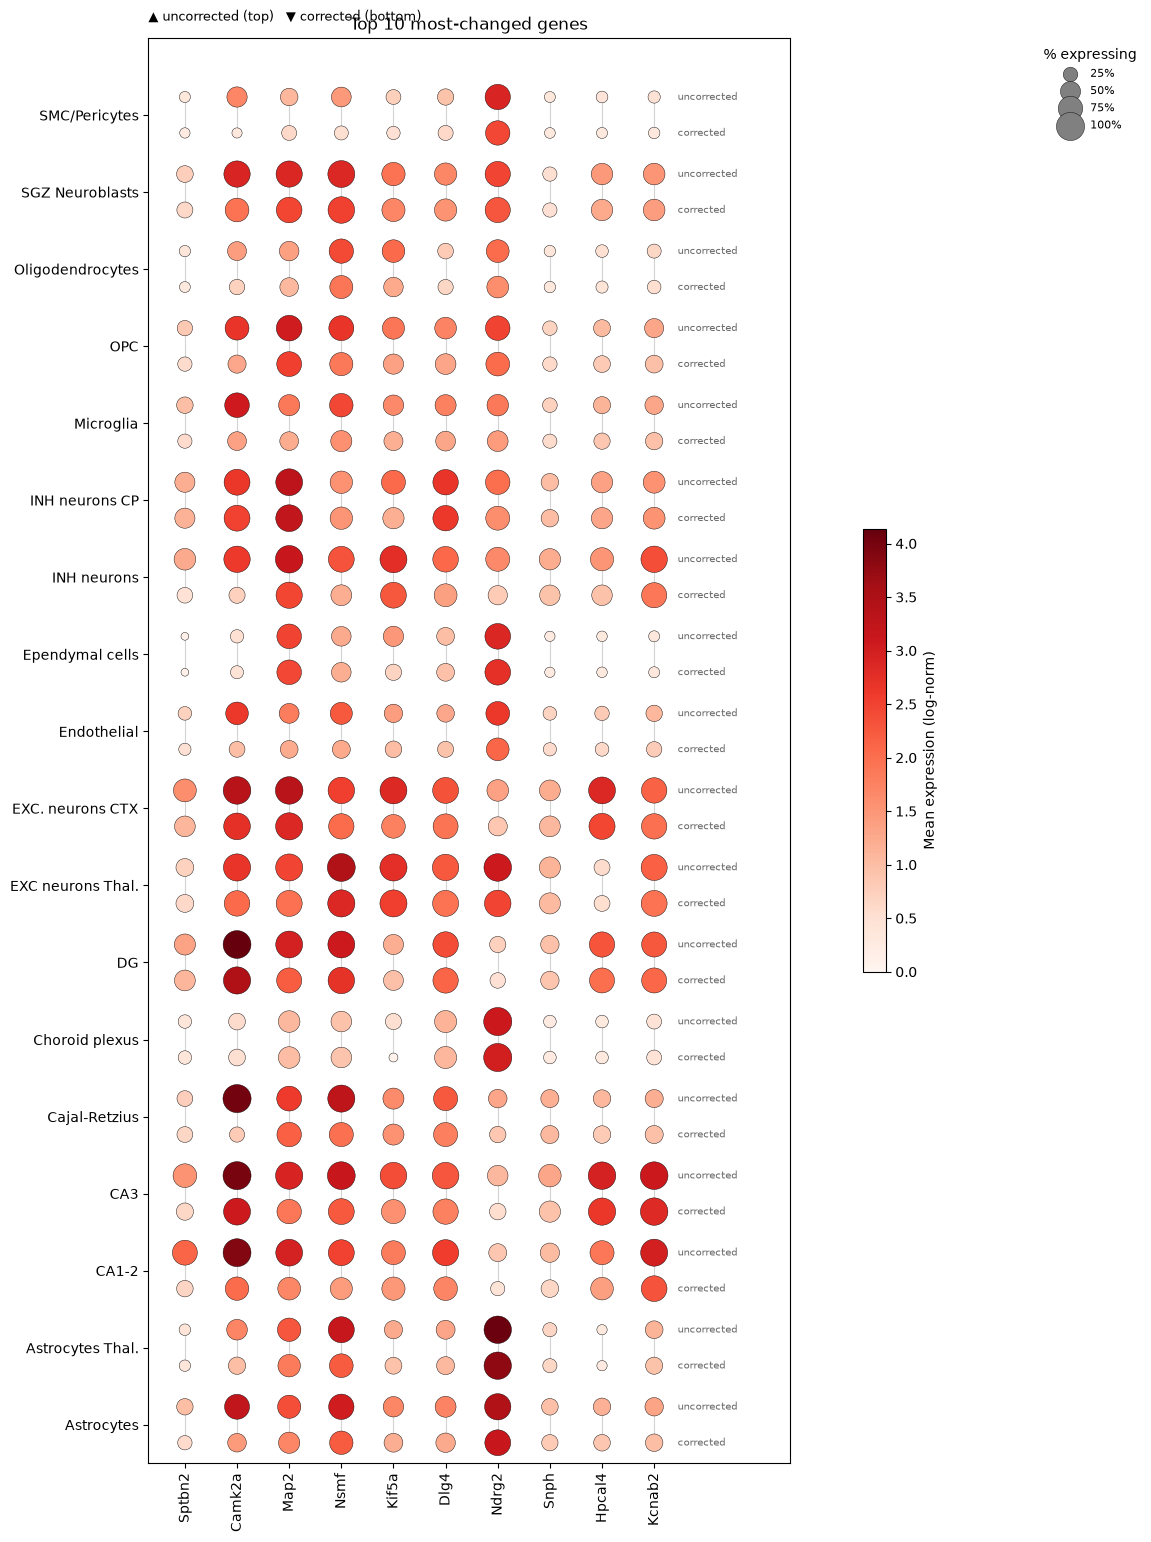

In [17]:
top5_dotplot_genes = top_genes["gene"].head(5).tolist()
paired_dotplot_combined(top5_dotplot_genes, "Top 5 most-changed genes", "top5_changed_genes_dotplot_paired.pdf")

top10_dotplot_genes = top_genes["gene"].head(10).tolist()
paired_dotplot_combined(top10_dotplot_genes, "Top 10 most-changed genes", "top10_changed_genes_dotplot_paired.pdf")


### Genes with the smallest correction (least affected) -- paired, uncorrected vs. corrected

Same reasonably-expressed gene set (`raw_total >= MIN_RAW_TOTAL`), sorted by `fraction_removed` ascending. Expect the two dots in each pair to sit almost on top of each other.

In [18]:
N_DOTPLOT_GENES = 10
bottom_genes = gene_df_f.sort_values("fraction_removed", ascending=True).head(N_DOTPLOT_GENES)
bottom_genes[["gene", "raw_total", "corrected_total", "fraction_removed"]]


,gene,raw_total,corrected_total,fraction_removed
2151,Igsf5,73.0,72.997278,0.000037
81,Adamts14,80.0,79.996600,0.000043
3895,Sec1,90.0,89.994470,0.000061
4372,Tas1r3,67.0,66.995717,0.000064
2565,Lrp2,71.0,70.992691,0.000103
3382,Plekhg4,66.0,65.993008,0.000106
4687,Usp18,82.0,81.989275,0.000131
4389,Tbx6,82.0,81.988741,0.000137
205,Ang,102.0,101.985795,0.000139
665,Cd37,230.0,229.952117,0.000208


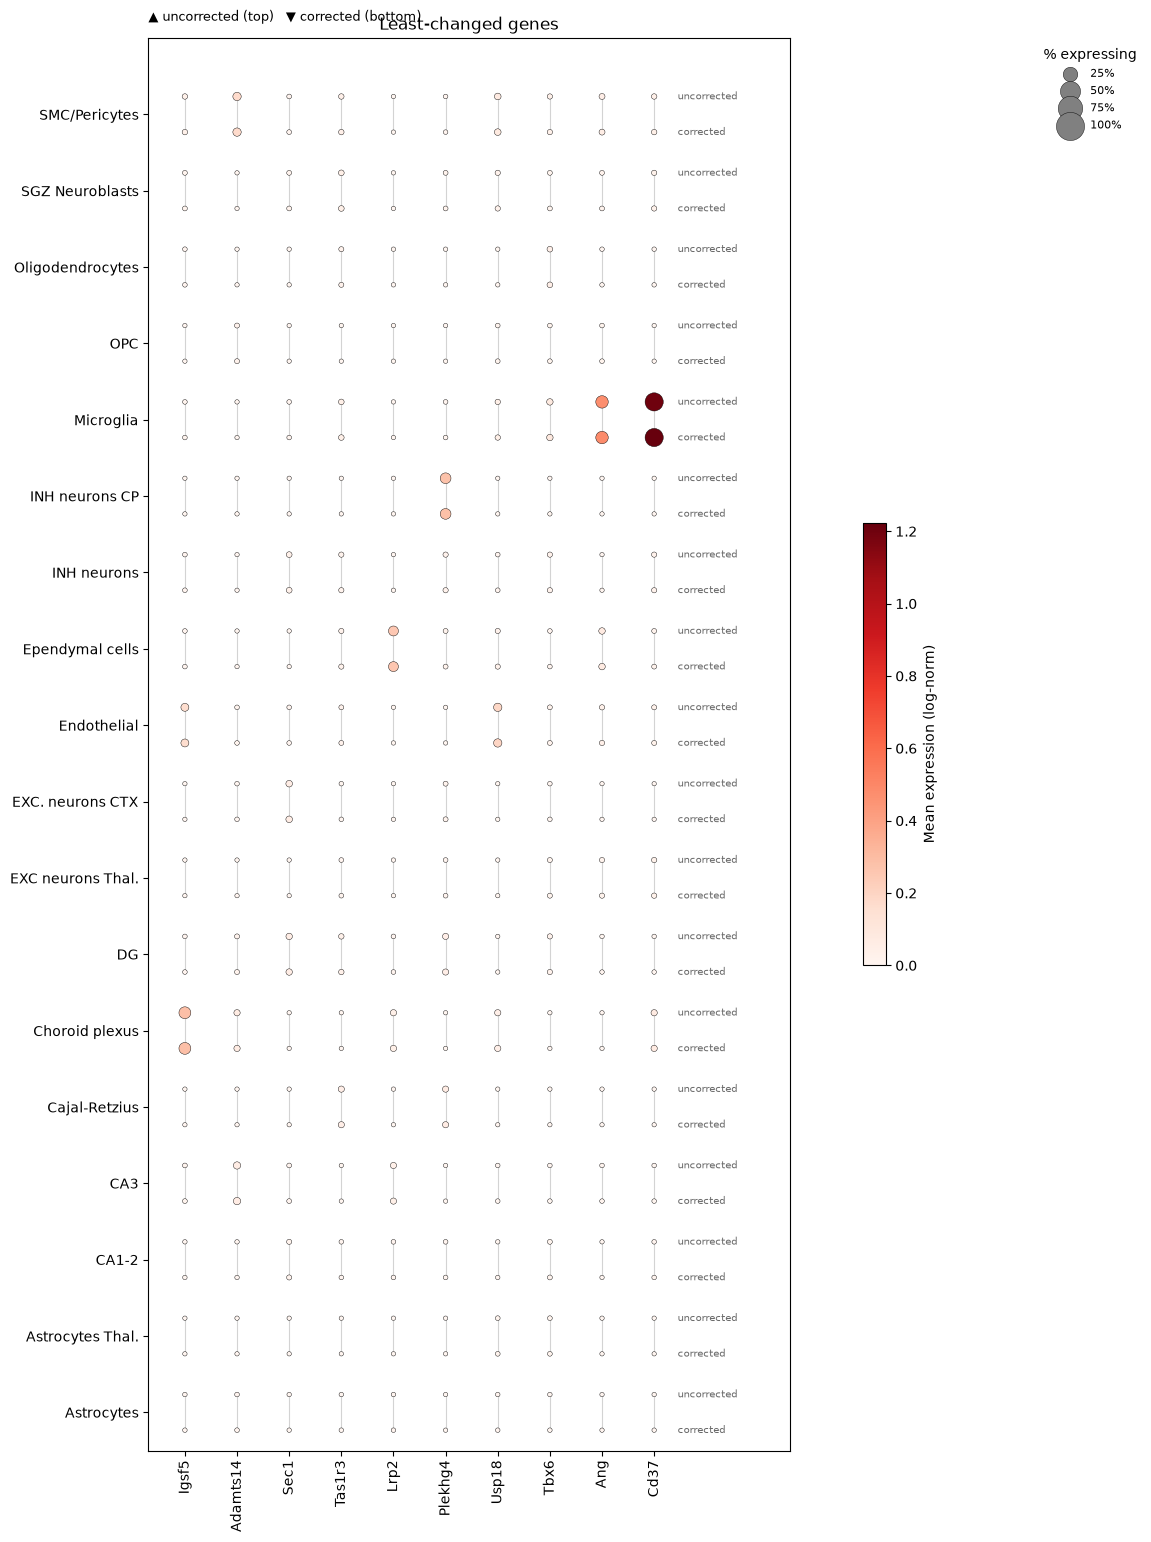

In [19]:
bottom_dotplot_genes = bottom_genes["gene"].tolist()
paired_dotplot_combined(bottom_dotplot_genes, "Least-changed genes", "least_changed_genes_dotplot_paired.pdf")


## Summary

- Full per-gene table: `local_background_gene_changes.csv`
- Full per-cell table: `local_background_cell_changes.csv`
- Figures: `top_changed_genes_barh.pdf`, `raw_vs_corrected_scatter.png`, `top_changed_cells_barh.png`, `celltype_by_gene_pct_change_heatmap.png`, `celltype_by_gene_raw_vs_corrected_heatmap.png`, `umap_cell_types.png`, `umap_top_genes_raw_vs_decontaminated.png`, `top_changed_genes_dotplot_raw.png`, `top_changed_genes_dotplot_decontaminated.png`, `least_changed_genes_dotplot_raw.png`, `least_changed_genes_dotplot_decontaminated.png`

All saved under `saving_path` (Lustre `ms_figures/xenium_msbrain_5k/local_urna_background_decontamination/`).